<a href="https://colab.research.google.com/github/sancheznaranjoyairchayanne-design/tecnm-desarrollo-web/blob/main/laboratorios/sesion07/sesion07_laboratorio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🧪 Sesión 07 · Especificación OpenAPI (Swagger) y ReDoc

**Desarrollo de Aplicaciones Web (DAB-2201)** · TecNM Cancún  
**Docente:** MCC. Iván Márquez Larios (`ijmarquezl`)  
**Repositorio:** https://github.com/ijmarquezl/tecnm-desarrollo-web

> **La pregunta de hoy:** ¿Cómo puede un cliente saber qué endpoints existen sin leer tu código? = Un cliente puede conocer los endpoints de una API consultando su especificación OpenAPI, generada automáticamente por FastAPI. Esta especificación se publica en /openapi.json y puede visualizarse mediante Swagger UI (/docs) o ReDoc (/redoc), permitiendo explorar y probar la API sin necesidad de leer el código fuente.

---

## 🖥️ Así se verá el resultado final

```json
GET /openapi.json  ->  HTTP 200

{
  "openapi": "3.1.0",
  "info": {
    "title": "Biblioteca API",
    "version": "1.0.0",
    "description": "API de libros del curso DAB-2201"
  },
  "paths": {
    "/api/libros": {
      "get":  {"summary": "Listar libros",  "responses": {"200": {...}}},
      "post": {"summary": "Crear un libro", "responses": {"201": {...}}}
    }
  },
  "components": {
    "schemas": {"Libro": {"type": "object", ...}}
  }
}

GET /docs   ->  HTTP 200 (Swagger UI)
GET /redoc  ->  HTTP 200 (ReDoc)
```

_La documentación no se escribe aparte: se genera del mismo código que atiende las peticiones._

**No hay pasos intermedios.** El cuaderno declara el resultado que debe existir al final; tú decides la estructura, los modelos y el orden de tu implementación. La celda de verificación compara tu resultado con este contrato.

---

## 🎯 Al finalizar podrás

- Publicar una especificación OpenAPI viva.
- Documentar endpoints, modelos y códigos de respuesta.
- Verificar que Swagger UI y ReDoc consumen esa especificación.

## ✅ Criterios de aceptación

El verificador ejecutará estos casos. Cada uno debe quedar en verde:

- [ ] OpenAPI responde con metadatos → HTTP 200
- [ ] Swagger UI está disponible → HTTP 200
- [ ] ReDoc está disponible → HTTP 200
- [ ] El endpoint documentado responde → HTTP 200

## 🧩 El reto

Publica una API de libros con metadatos y modelos documentados. El contrato debe describir lo que el servidor realmente hace.

**Requisitos del contrato**

- La app se llama «Biblioteca API», versión 1.0.0, con una descripción.
- GET /openapi.json responde 200 y contiene las rutas /api/libros.
- El esquema `Libro` aparece en components.schemas porque un endpoint lo usa.
- GET /docs y GET /redoc responden 200.
- GET /api/libros responde 200 con el listado.

> **Pista conceptual:** En FastAPI, `title`, `version`, `description` y los modelos Pydantic alimentan OpenAPI automáticamente. Si el contrato y el código se contradicen, el contrato miente.

## 📦 Entregable

Cuaderno en verde y bitácora `auditorias/auditoria_sesion07.md` con la captura del contrato.


## ⚙️ Preparación del entorno

Ejecuta esta celda una sola vez. Instala las herramientas del track **Python / FastAPI** y descarga el motor de verificación del repositorio. No necesitas instalar nada en tu computadora: todo corre en Colab.


In [13]:
import os, sys
print("⏳ Preparando el entorno de Desarrollo Web...")
!pip install -q fastapi uvicorn httpx pydantic "passlib[bcrypt]" bcrypt python-jose[cryptography] PyJWT "sqlalchemy[asyncio]" greenlet aiosqlite alembic python-multipart
!wget -q -O verificar.py https://raw.githubusercontent.com/ijmarquezl/tecnm-desarrollo-web/c275993ba69ef2a8cf650b2f127b55c8356279d7/laboratorios/verificar.py
if not os.path.exists("verificar.py") or os.path.getsize("verificar.py") < 1000:
    raise RuntimeError("No se pudo descargar verificar.py. Revisa tu conexión o abre el cuaderno desde el repositorio del curso.")
print("✅ Entorno listo")
print("Python:", sys.version.split()[0])
print("Motor de verificación:", os.path.getsize("verificar.py"), "bytes")


⏳ Preparando el entorno de Desarrollo Web...
✅ Entorno listo
Python: 3.13.18
Motor de verificación: 13395 bytes


## 🧩 El reto: escribe el resultado

Crea el o los archivos del contrato. No hay una plantilla de pasos: el esqueleto solo te da el punto de partida. Todo lo que sigue lo decides tú.

**Archivos que debes producir:** `app.py`


### 📄 `app.py`

Archivo principal de la implementación.

In [16]:
%%writefile app.py
from typing import List

from fastapi import FastAPI
from pydantic import BaseModel

app = FastAPI(
    title="Biblioteca API",
    version="1.0.0",
    description="API de libros del curso DAB-2201"
)

class Libro(BaseModel):
    id: int
    titulo: str
    autor: str

class ListaLibrosResponse(BaseModel):
    libros: List[Libro]

@app.get(
    "/api/libros",
    tags=["libros"],
    response_model=ListaLibrosResponse
)
def listar_libros():
    return {"libros": []}

Overwriting app.py


## 🧪 Tu contrato C-R-E-O

Antes de pedir ayuda a la IA, escribe el contrato que describe el resultado. Esto alimenta tu bitácora y te obliga a pensar como arquitecto:

| Elemento | Tu definición |
| :--- | :--- |
| **Contexto** | Desarrollo de una API REST utilizando FastAPI y Pydantic en Google Colab. La aplicación debe generar automáticamente la documentación OpenAPI 3.1.0 y exponer Swagger UI y ReDoc. El archivo principal es app.py y debe cumplir las validaciones del verificador del curso DAB-2201|
| **Rol** |Actuar como desarrollador backend especializado en FastAPI, diseñando una API documentada cuyo contrato OpenAPI refleje exactamente el comportamiento real de los endpoints. |
| **Especificación** | Crear una aplicación llamada Biblioteca API, versión 1.0.0, con descripción. Implementar el endpoint GET /api/libros que responda HTTP 200 con {"libros": []}. Definir el modelo Pydantic Libro para que aparezca documentado en components.schemas. Garantizar que /openapi.json, /docs y /redoc respondan correctamente. |
| **Output** |Archivo app.py funcional que genere automáticamente la especificación OpenAPI, incluya el esquema Libro en la documentación y permita superar los 4 casos de verificación del laboratorio. |

> No pegues código de la IA sin auditarlo. La responsabilidad técnica del resultado es tuya.


## 🔍 Verificación del resultado

Ejecuta esta celda cuando tu implementación esté lista. La verificación no modifica tu código: solo observa el comportamiento y compara con el contrato. Si algo falla, el mensaje te dice **qué esperaba** y **qué recibió**.


In [17]:
from verificar import probar_http

casos = [{'descripcion': 'OpenAPI responde con metadatos',
  'metodo': 'GET',
  'ruta': '/openapi.json',
  'estado': 200,
  'json_contiene': {'openapi': '3.1.0',
                    'info': {'title': 'Biblioteca API', 'version': '1.0.0'},
                    'paths': {'/api/libros': {}},
                    'components': {'schemas': {'Libro': {}}}}},
 {'descripcion': 'Swagger UI está disponible',
  'metodo': 'GET',
  'ruta': '/docs',
  'estado': 200,
  'cuerpo_contiene': ['swagger']},
 {'descripcion': 'ReDoc está disponible', 'metodo': 'GET', 'ruta': '/redoc', 'estado': 200},
 {'descripcion': 'El endpoint documentado responde',
  'metodo': 'GET',
  'ruta': '/api/libros',
  'estado': 200,
  'json_contiene': {'libros': []}}]

probar_http(casos, archivo="app.py", limpiar=[], env={})


VERIFICACIÓN DEL RESULTADO · 4 casos · app.py
✅ 01. OpenAPI responde con metadatos
✅ 02. Swagger UI está disponible
✅ 03. ReDoc está disponible
✅ 04. El endpoint documentado responde
------------------------------------------------------------------------------
RESULTADO: 4/4 casos correctos. ¡Resultado logrado!


## 📝 Cierre y bitácora

1. Copia la plantilla `plantillas/auditoria_sesion07.md` a `auditorias/auditoria_sesion07.md` en tu fork.
2. Responde con tus palabras:
   - ¿Qué resultado te costó más alcanzar y por qué? = Lo que más me costó fue comprender cómo FastAPI genera automáticamente la documentación OpenAPI. Al inicio pensaba que debía crear el archivo JSON manualmente, pero descubrí que se produce a partir de los modelos Pydantic y las rutas definidas en la aplicación

   - ¿Qué decisión de diseño tomaste que no estaba escrita en el contrato? = Decidí crear un modelo Libro con los campos id, titulo y autor para que el esquema apareciera documentado dentro de components.schemas y mantener una estructura coherente para futuras ampliaciones de la API

   - ¿Qué error detectó la verificación que tú no habías previsto? =
La verificación exige que el endpoint /api/libros devuelva exactamente una estructura JSON con la clave libros. Inicialmente devolvía una lista vacía directamente y el verificador la rechazó porque el formato no coincidía con el contrato esperado.

3. Haz commit de tu cuaderno ejecutado y de tu bitácora.

**La sesión termina cuando el resultado está en verde, no cuando el código "parece funcionar".**
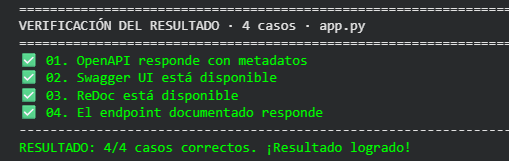